# 06. K-Medoids (PAM): medoid sebagai pusat kelompok

K-Medoids ditambahkan sebagai pembanding bagi K-Means dan DBSCAN. Data, lima fitur standar, jarak Euclidean, kandidat k, dan aturan seleksi sama dengan K-Means; pusat kelompok berupa kotak-triwulan nyata. Data yang dipakai tetap training 2021-2025.

**Baca berurutan:** [konsep](#s2) → [jalankan](#s5) → [verifikasi medoid](#s6) → [tabel nama kelompok](#s8) → [pemilihan k dan gambar cluster](#s9). Hasil tampil di bawah sel kode.

[Panduan](../00_panduan.ipynb) | [Sebelumnya](../05_dbscan/05_dbscan.ipynb) | [Berikutnya](../07_model_evaluation/07_model_evaluation.ipynb)

### Daftar bagian

- [1. Inisialisasi dan dependensi](#s1)
- [2. Konsep K-Medoids dan perbedaannya dengan K-Means](#s2)
- [3. Kode algoritma PAM](#s3)
- [4. Kode evaluasi dan pencarian k](#s4)
- [5. Jalankan K-Medoids](#s5)
- [6. Verifikasi medoid dan hasil](#s6)
- [7. Penamaan dan interpretasi kelompok (setelah clustering)](#s7)
- [8. Tabel nama kelompok dan angka dasarnya](#s8)
- [9. Lihat pemilihan k dan gambar cluster](#s9)

**Aturan nama:** frekuensi dan magnitudo rendah/sedang/tinggi adalah peringkat relatif rata-rata kelompok di dalam model yang sama, bukan ambang seismologi. Posisi = (peringkat rata-rata - 1) / (jumlah kelompok - 1): rendah ? 1/3, sedang > 1/3 dan < 2/3, tinggi ? 2/3; nilai sama memakai peringkat rata-rata. Noise tidak diikutkan. Dengan hanya dua kelompok, rendah dan tinggi hanya menunjukkan urutan, bukan besar selisih atau signifikansi. Kategori kedalaman memakai rata-rata kelompok: dangkal < 70 km, menengah 70 sampai < 300 km, dan dalam ? 300 km; ini tidak berarti seluruh kejadian mempunyai kategori kedalaman yang sama. Nama tidak menyatakan tingkat bahaya.

<a id="s1"></a>
## 1. Inisialisasi dan dependensi

Jalankan dari atas ke bawah dengan kernel Python 3.12.11 (Seismic Research). Konfigurasi tersentral di config.json.

In [1]:
from pathlib import Path
import os
import sys

os.environ.setdefault("LOKY_MAX_CPU_COUNT", "2")
os.environ.setdefault("OMP_NUM_THREADS", "2")
candidates = []
for parent in [Path.cwd(), *Path.cwd().parents]:
    candidates.extend([parent, parent / "seismic_research_2021_2025"])
ROOT = next((p for p in candidates if (p / "config.json").is_file() and (p / "src/common.py").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Buka notebook dari folder proyek seismic_research_2021_2025.")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from IPython.display import display, Image, Markdown, FileLink
from src.common import read_config
cfg = read_config(ROOT)
print("Interpreter:", sys.executable)
print("Python:", sys.version.split()[0])
print("Proyek:", ROOT)
print("Training:", cfg["train_start"], "sampai sebelum", cfg["train_end_exclusive"])
print("Testing sampai sebelum (UTC):", cfg["test_end_exclusive"])

import json
from pathlib import Path
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.cluster import DBSCAN, KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import davies_bouldin_score, silhouette_score
from sklearn.neighbors import NearestNeighbors
from threadpoolctl import threadpool_limits
from src.common import ROOT, load_prepared, save_model_metadata
from src.kmedoids import KMedoids

Interpreter: C:\Users\yudhi\.local\bin\python3.12.exe
Python: 3.12.11
Proyek: C:\Users\yudhi\Documents\machine-learning
Training: 2021-01-01 sampai sebelum 2026-01-01
Testing sampai sebelum (UTC): 2026-10-26


<a id="s2"></a>
## 2. Konsep K-Medoids dan perbedaannya dengan K-Means

K-Medoids memilih **k observasi nyata sebagai pusat kelompok (medoid)** dan meminimalkan jumlah jarak setiap observasi ke medoid kelompoknya:

$$\min_{M \subset X,\ |M|=k} \; \sum_{i=1}^{n} \min_{m \in M} d(x_i, m)$$

K-Means meminimalkan jumlah **kuadrat** jarak ke rata-rata (centroid) yang berupa titik hitung, bukan observasi. Dua perbedaan ini menentukan cara membaca hasil:

| Aspek | K-Means | K-Medoids (PAM) |
| --- | --- | --- |
| Pusat kelompok | Rata-rata anggota (titik hitung) | Satu observasi nyata, yaitu satu kotak-triwulan |
| Fungsi tujuan | Jumlah jarak kuadrat | Jumlah jarak (tanpa kuadrat) |
| Pengaruh pencilan | Rata-rata ikut tertarik pencilan | Medoid tetap berupa titik data; pencilan jauh lebih kecil pengaruhnya |
| Inisialisasi | Acak (n_init=20) | BUILD deterministik, sehingga hasil tidak bergantung seed awal |
| Biaya hitung | O(n k) per iterasi | O(n^2) per sapuan SWAP |
| Interpretasi | Profil rata-rata | Ada kotak-triwulan contoh yang dapat dibuka di peta dan dicek ke katalog |

**Algoritma PAM** (Kaufman & Rousseeuw, 1990). Tahap BUILD memilih medoid pertama yang meminimalkan jumlah jarak ke seluruh titik, lalu menambah medoid satu per satu yang paling menurunkan biaya. Tahap SWAP menukar medoid dengan non-medoid selama biaya total turun. Evaluasi SWAP memakai rumus delta-biaya FastPAM (Schubert & Rousseeuw, 2021) sehingga setiap kandidat dinilai terhadap semua medoid dalam satu lintasan O(n).

**Pengaturan agar sebanding dengan K-Means dan DBSCAN:**

- Data: lima fitur standar dari training 2021-2025, sama persis dengan model lain.
- Jarak: Euclidean pada ruang fitur standar, sama dengan jarak yang dipakai Silhouette dan Davies-Bouldin.
- Kandidat k: 2 sampai 8. Aturan pemilihan identik dengan K-Means: rata-rata Silhouette tiga sampel tertinggi, lalu DBI terendah, lalu k terkecil.
- Matriks jarak penuh tidak disimpan. Baris jarak dihitung per potongan sehingga memori tetap kecil untuk 13 ribu lebih baris.
- Implementasi ditulis sendiri di `src/kmedoids.py` karena `scikit-learn-extra` tidak tersedia untuk scikit-learn versi ini. Kebenarannya diuji pada `tests/test_kmedoids.py`, termasuk pembandingan dengan solusi optimum hasil pencarian menyeluruh pada data kecil.


<a id="s3"></a>
## 3. Kode algoritma PAM

Implementasi lengkap ada di `src/kmedoids.py` dan ditampilkan apa adanya di bawah. Kelas ini mengikuti antarmuka scikit-learn (`fit`, `predict`, `labels_`, `cluster_centers_`) sehingga dapat dipakai pada pengujian 2026 seperti K-Means.

In [2]:
import inspect

display(Markdown("```python\n" + inspect.getsource(KMedoids) + "\n```"))


```python
class KMedoids(ClusterMixin, BaseEstimator):
    """Pengelompokan K-Medoids PAM; pusat kelompok selalu berupa observasi nyata."""

    def __init__(self, n_clusters=3, max_iter=100, random_state=42, chunk_size=256, tol=1e-10):
        self.n_clusters = n_clusters
        self.max_iter = max_iter
        self.random_state = random_state
        self.chunk_size = chunk_size
        self.tol = tol

    def _build(self, X):
        n, k = len(X), self.n_clusters
        totals = np.concatenate([cdist(X[a:a + self.chunk_size], X).sum(axis=1) for a in range(0, n, self.chunk_size)])
        medoids = [int(np.argmin(totals))]
        nearest = cdist(X, X[medoids]).ravel()
        while len(medoids) < k:
            gains = np.concatenate([np.maximum(nearest[None, :] - cdist(X[a:a + self.chunk_size], X), 0).sum(axis=1)
                                    for a in range(0, n, self.chunk_size)])
            gains[medoids] = -np.inf
            chosen = int(np.argmax(gains))
            medoids.append(chosen)
            nearest = np.minimum(nearest, cdist(X, X[[chosen]]).ravel())
        return np.array(medoids, dtype=int)

    @staticmethod
    def _assign(X, medoids):
        distances = cdist(X, X[medoids])
        order = np.argsort(distances, axis=1)[:, :2]
        rows = np.arange(len(X))
        return order[:, 0], distances[rows, order[:, 0]], distances[rows, order[:, 1]]

    def fit(self, X, y=None):
        X = np.ascontiguousarray(X, dtype=float)
        n, k = X.shape[0], self.n_clusters
        if not 2 <= k <= n:
            raise ValueError("n_clusters harus berada pada rentang 2..jumlah observasi.")
        medoids = self._build(X)
        near, nearest, second = self._assign(X, medoids)
        rng = np.random.default_rng(self.random_state)
        swaps, passes = 0, 0
        for passes in range(1, self.max_iter + 1):
            improved = False
            order = rng.permutation(n)
            for start in range(0, n, self.chunk_size):
                candidates = order[start:start + self.chunk_size]
                block = cdist(X[candidates], X)
                for row, candidate in enumerate(candidates):
                    if candidate in medoids:
                        continue
                    d = block[row]
                    gain_others = np.minimum(d - nearest, 0.0)
                    extra = np.minimum(d, second) - nearest - gain_others
                    delta = gain_others.sum() + np.bincount(near, weights=extra, minlength=k)
                    best = int(np.argmin(delta))
                    if delta[best] < -self.tol:
                        medoids[best] = candidate
                        near, nearest, second = self._assign(X, medoids)
                        swaps += 1
                        improved = True
            if not improved:
                break
        self.medoid_indices_ = medoids
        self.cluster_centers_ = X[medoids].copy()
        self.labels_ = near.astype(int)
        self.inertia_ = float(nearest.sum())
        self.n_iter_ = passes
        self.n_swaps_ = swaps
        return self

    def transform(self, X):
        return cdist(np.asarray(X, dtype=float), self.cluster_centers_)

    def predict(self, X):
        return self.transform(X).argmin(axis=1)

```

<a id="s4"></a>
## 4. Kode evaluasi dan pencarian k

Fungsi evaluasi dan pemilihan k identik dengan K-Means: rata-rata Silhouette tiga sampel, DBI pada seluruh baris, tie-break DBI lalu k terkecil. Hanya model dan nama berkas yang berbeda.

In [3]:
def cluster_metrics(X, labels, sample_size=2000, seed=42):
    X, labels = np.asarray(X), np.asarray(labels)
    assigned = labels >= 0
    values, counts = np.unique(labels[assigned], return_counts=True)
    result = {"n_rows": len(labels), "n_clusters": len(values), "n_assigned": int(assigned.sum()),
              "noise_fraction": float((~assigned).mean()),
              "largest_cluster_fraction_assigned": float(counts.max()/counts.sum()) if len(counts) else np.nan,
              "smallest_cluster_size": int(counts.min()) if len(counts) else 0,
              "silhouette": np.nan, "davies_bouldin": np.nan, "silhouette_n": 0}
    if len(values) < 2 or assigned.sum() <= len(values):
        return result
    xx, yy = X[assigned], labels[assigned]
    rng = np.random.default_rng(seed)
    indices = rng.choice(len(xx), min(sample_size, len(xx)), replace=False)
    observed = len(np.unique(yy[indices]))
    if 1 < observed < len(indices):
        result["silhouette"] = float(silhouette_score(xx[indices], yy[indices]))
        result["silhouette_n"] = len(indices)
    result["davies_bouldin"] = float(davies_bouldin_score(xx, yy))
    return result

def full_labels(panel, train, labels, method):
    values = train[["row_id"]].copy()
    values["cluster"] = labels
    result = panel.loc[panel["split"].eq("train")].merge(values, on="row_id", how="left", validate="one_to_one")
    result["profile"] = result["state"]
    valid = result["cluster"].notna()
    result.loc[valid, "profile"] = result.loc[valid, "cluster"].astype(int).map(
        lambda n: "NOISE" if n < 0 else f"{method.upper()}_P{n}")
    return result

def profile_table(result, features):
    eligible = result.loc[result["cluster"].notna()]
    table = eligible.groupby("profile")[features + ["earthquake_count", "frequency_per_month", "depth_coverage"]].mean()
    table["n_grid_quarters"] = eligible.groupby("profile").size()
    table["low_support_fraction"] = eligible.groupby("profile")["low_support"].mean()
    return table.reset_index()

def save_cluster_plot(root, method, X, labels):
    projection = PCA(n_components=2, random_state=42).fit_transform(X)
    fig, ax = plt.subplots(figsize=(9, 6))
    for label in sorted(np.unique(labels)):
        mask = labels == label
        ax.scatter(projection[mask, 0], projection[mask, 1], s=7, alpha=.45,
                   label=("Noise" if label < 0 else f"Profil {label}") if len(np.unique(labels)) <= 20 else None)
    ax.set(xlabel="PC1", ylabel="PC2", title=f"{method.upper()}: proyeksi PCA fitur training (bukan koordinat)")
    if len(np.unique(labels)) <= 20:
        ax.legend()
    fig.tight_layout()
    fig.savefig(Path(root) / f"reports/figures/{method}_pca.png", dpi=160)
    plt.close(fig)

def export_kmedoids_matched_tables(directory, panel, train, model, features):
    """Export profiles and medoids for the fixed-k comparison model."""
    directory = Path(directory)
    labels = full_labels(panel, train, model.labels_, "kmedoids_matched_k")
    labels.to_csv(directory / "training_labels_matched_k.csv", index=False)
    profile_table(labels, features).to_csv(directory / "profiles_matched_k.csv", index=False)
    columns = ["row_id", "grid_id", "period", "earthquake_count", "frequency_per_month"] + features
    medoids = train.iloc[model.medoid_indices_][columns].copy()
    medoids.insert(0, "cluster", range(len(medoids)))
    medoids.to_csv(directory / "medoids_matched_k.csv", index=False)
    return labels

def fit_kmedoids(root=ROOT):
    root = Path(root)
    cfg, panel, train, X, _, meta = load_prepared(root)
    rows, fitted = [], {}
    unique_count = len(np.unique(X, axis=0))
    with threadpool_limits(limits=2):
        for k in cfg["k_candidates"]:
            if not 2 <= k < min(len(X), unique_count + 1):
                continue
            model = KMedoids(n_clusters=k, random_state=cfg["random_state"]).fit(X)
            fitted[k] = model
            metrics = cluster_metrics(X, model.labels_, cfg["silhouette_sample_size"])
            repeat_scores = [cluster_metrics(X, model.labels_, cfg["silhouette_sample_size"], seed)["silhouette"] for seed in cfg["silhouette_seeds"]]
            metrics["silhouette"] = float(np.nanmean(repeat_scores))
            metrics["silhouette_std"] = float(np.nanstd(repeat_scores))
            rows.append({"k": k, "total_distance": model.inertia_, "n_swaps": model.n_swaps_, **metrics})
        scores = pd.DataFrame(rows)
        valid = scores.loc[scores["silhouette"].notna()]
        if valid.empty:
            raise ValueError("K-Medoids tidak menghasilkan kandidat evaluasi yang valid.")
        selected = valid.sort_values(["silhouette", "davies_bouldin", "k"], ascending=[False, True, True]).iloc[0]
        model = fitted[int(selected["k"])]
    kmeans_meta = root / "models/kmeans/metadata.json"
    matched_k = json.loads(kmeans_meta.read_text(encoding="utf-8"))["selected_k"] if kmeans_meta.exists() else None
    result = full_labels(panel, train, model.labels_, "kmedoids")
    directory = root / "models/kmedoids"
    directory.mkdir(parents=True, exist_ok=True)
    scores.to_csv(directory / "parameter_search.csv", index=False)
    result.to_csv(directory / "training_labels.csv", index=False)
    profile_table(result, cfg["features"]).to_csv(directory / "profiles.csv", index=False)
    medoids = train.iloc[model.medoid_indices_][["row_id", "grid_id", "period", "earthquake_count", "frequency_per_month"] + cfg["features"]].copy()
    medoids.insert(0, "cluster", range(len(medoids)))
    medoids.to_csv(directory / "medoids.csv", index=False)
    joblib.dump(model, directory / "model.joblib")
    matched_path = directory / "model_matched_k.joblib"
    if matched_k in fitted:
        matched_model = fitted[matched_k]
        joblib.dump(matched_model, matched_path)
        export_kmedoids_matched_tables(directory, panel, train, matched_model, cfg["features"])
    elif matched_path.exists():
        matched_path.unlink()
    save_model_metadata(root, "kmedoids", meta, {"selected_k": int(selected["k"]), "matched_k_with_kmeans": matched_k if matched_k in fitted else None,
                        "algorithm": "PAM: BUILD deterministik + SWAP FastPAM, jarak Euclidean",
                        "selection": "rata-rata silhouette 3 sampel tertinggi; tie-break DBI terendah dan k terkecil", "fit_split": "train"})
    fig, axes = plt.subplots(1, 3, figsize=(14, 4))
    for ax, metric in zip(axes, ["total_distance", "silhouette", "davies_bouldin"]):
        ax.plot(scores["k"], scores[metric], marker="o")
        ax.axvline(int(selected["k"]), color="gray", ls="--")
        ax.set(xlabel="k", ylabel=metric, title=metric)
    fig.tight_layout()
    fig.savefig(root / "reports/figures/kmedoids_selection.png", dpi=160)
    plt.close(fig)
    save_cluster_plot(root, "kmedoids", X, model.labels_)
    return scores, result

<a id="s5"></a>
## 5. Jalankan K-Medoids

Menjalankan pencarian k=2..8 sekaligus menyimpan model, label, profil, dan medoid. Proses PAM memerlukan beberapa menit pada seluruh training.

In [4]:
from scipy.spatial.distance import cdist
from src.common import load_model

search, labels = fit_kmedoids(ROOT)
kmedoids_cfg, kmedoids_panel, kmedoids_train, kmedoids_X, _, _ = load_prepared(ROOT)
kmedoids_model, kmedoids_metadata = load_model(ROOT, "kmedoids")
display(Markdown("### Seluruh kandidat k"))
display(search)
display(Markdown("### Profil rata-rata setiap kelompok (satuan asli)"))
display(pd.read_csv(ROOT / "models/kmedoids/profiles.csv"))
if kmedoids_metadata.get("matched_k_with_kmeans") is not None:
    display(Markdown(f"### Profil kontrol k={kmedoids_metadata['matched_k_with_kmeans']} (bukan k terpilih)"))
    display(pd.read_csv(ROOT / "models/kmedoids/profiles_matched_k.csv"))
    display(Markdown("### Medoid kontrol: kotak-triwulan nyata"))
    display(pd.read_csv(ROOT / "models/kmedoids/medoids_matched_k.csv"))


### Seluruh kandidat k

,k,total_distance,n_swaps,n_rows,n_clusters,n_assigned,noise_fraction,largest_cluster_fraction_assigned,smallest_cluster_size,silhouette,davies_bouldin,silhouette_n,silhouette_std
0,2,21986.288654,6,13471,2,13471,0.0,0.748719,3385,0.395606,1.248097,2000,0.010753
1,3,18126.042052,15,13471,3,13471,0.0,0.400193,3052,0.333091,1.143022,2000,0.004239
2,4,16127.491342,18,13471,4,13471,0.0,0.354168,2831,0.354014,1.037873,2000,0.002143
3,5,14821.792200,19,13471,5,13471,0.0,0.244228,2030,0.288980,1.023363,2000,0.000382
4,6,13614.239350,19,13471,6,13471,0.0,0.244971,1163,0.314139,1.045888,2000,0.002844
5,7,12667.381251,28,13471,7,13471,0.0,0.242818,550,0.333356,0.957359,2000,0.003408
6,8,11853.581813,22,13471,8,13471,0.0,0.195086,550,0.336115,0.964415,2000,0.004187


### Profil rata-rata setiap kelompok (satuan asli)

,profile,log_frequency,avg_magnitude,max_magnitude,avg_depth,shallow_fraction,earthquake_count,frequency_per_month,depth_coverage,n_grid_quarters,low_support_fraction
0,KMEDOIDS_P0,0.553612,3.638610,3.887864,23.153060,0.958774,2.789213,0.929738,1.0,10086,0.861987
1,KMEDOIDS_P1,0.511896,3.926268,4.156662,192.197796,0.081201,2.367504,0.789168,1.0,3385,0.876809


### Profil kontrol k=6 (bukan k terpilih)

profile,log_frequency,avg_magnitude,max_magnitude,avg_depth,shallow_fraction,earthquake_count,frequency_per_month,depth_coverage,n_grid_quarters,low_support_fraction
KMEDOIDS_MATCHED_K_P0,0.529313,3.591801,3.801576,23.629556,0.947551,2.206970,0.735657,1.0,3300,0.961818
KMEDOIDS_MATCHED_K_P1,0.472229,4.245787,4.437411,240.116005,0.043569,1.998903,0.666301,1.0,1823,0.918815
KMEDOIDS_MATCHED_K_P2,0.346419,3.210240,3.230181,18.969365,0.986523,1.274288,0.424763,1.0,3088,0.999028
KMEDOIDS_MATCHED_K_P3,0.383466,3.381551,3.442648,152.744883,0.045180,1.478934,0.492978,1.0,1163,0.978504
KMEDOIDS_MATCHED_K_P4,1.187058,3.722807,4.610949,40.611235,0.807601,8.151338,2.717113,1.0,2055,0.266667
KMEDOIDS_MATCHED_K_P5,0.369138,4.358517,4.502742,23.862149,0.969719,1.377571,0.459190,1.0,2042,1.000000


### Medoid kontrol: kotak-triwulan nyata

cluster,row_id,grid_id,period,earthquake_count,frequency_per_month,log_frequency,avg_magnitude,max_magnitude,avg_depth,shallow_fraction
0,46_1|2022Q1,46_1,2022Q1,2,0.666667,0.510826,3.6,3.8,21.000000,1.000000
1,26_-6|2021Q1,26_-6,2021Q1,2,0.666667,0.510826,4.2,4.4,195.500000,0.000000
2,9_17|2021Q4,9_17,2021Q4,1,0.333333,0.287682,3.2,3.2,15.000000,1.000000
3,22_13|2023Q4,22_13,2023Q4,1,0.333333,0.287682,3.4,3.4,138.000000,0.000000
4,-17_-15|2021Q1,-17_-15,2021Q1,6,2.000000,1.098612,3.7,4.6,32.666667,0.833333
5,1_15|2024Q3,1_15,2024Q3,1,0.333333,0.287682,4.4,4.4,18.900000,1.000000


<a id="s6"></a>
## 6. Verifikasi medoid dan hasil

Pemeriksaan otomatis memastikan pusat kelompok benar-benar observasi data dan setiap baris berlabel medoid terdekat.

In [5]:
angka = lambda value, digits=4: f"{value:.{digits}f}".replace(".", ",")
jumlah = lambda value: f"{int(value):,}".replace(",", ".")
centers = kmedoids_model.cluster_centers_
assert kmedoids_model.n_clusters == kmedoids_metadata["selected_k"]
assert len(kmedoids_model.labels_) == len(kmedoids_X) == len(kmedoids_train)
assert len(set(kmedoids_model.medoid_indices_.tolist())) == kmedoids_model.n_clusters
assert np.allclose(centers, kmedoids_X[kmedoids_model.medoid_indices_]), "Pusat kelompok harus observasi nyata."
assert (cdist(kmedoids_X, centers).argmin(axis=1) == kmedoids_model.labels_).all(), "Setiap baris harus berlabel medoid terdekat."
assert np.isclose(kmedoids_model.inertia_, cdist(kmedoids_X, centers).min(axis=1).sum())
selected_row = search.loc[search["k"].eq(kmedoids_metadata["selected_k"])].iloc[0]
display(Markdown(f"""### Pemeriksaan hasil

- Jumlah kelompok terpilih: **{kmedoids_model.n_clusters}** (aturan seleksi sama dengan K-Means).
- Biaya total (jumlah jarak ke medoid): **{angka(kmedoids_model.inertia_, 1)}**.
- Pertukaran medoid sampai konvergen: **{kmedoids_model.n_swaps_}** pada **{kmedoids_model.n_iter_}** sapuan.
- Silhouette seleksi (rata-rata 3 sampel): **{angka(selected_row['silhouette'])}**; DBI: **{angka(selected_row['davies_bouldin'])}**.
- Pemeriksaan lulus: setiap pusat kelompok adalah satu observasi nyata, dan setiap baris berlabel medoid terdekat.
"""))
medoids = pd.read_csv(ROOT / "models/kmedoids/medoids.csv")
medoids["profile"] = medoids["cluster"].map(lambda number: f"KMEDOIDS_P{number}")
medoids["frekuensi_per_bulan"] = medoids["frequency_per_month"]
display(Markdown("### Medoid: kotak-triwulan nyata yang mewakili tiap kelompok"))
display(medoids[["profile", "grid_id", "period", "earthquake_count", "avg_magnitude", "max_magnitude", "avg_depth", "shallow_fraction"]].rename(columns={
    "profile": "Kode algoritma", "grid_id": "Kotak", "period": "Triwulan", "earthquake_count": "Jumlah gempa",
    "avg_magnitude": "Rata-rata M", "max_magnitude": "M terbesar", "avg_depth": "Rata-rata kedalaman (km)", "shallow_fraction": "Proporsi dangkal"}).round(3))
display(Markdown("Berbeda dari centroid K-Means, setiap baris di atas adalah kotak dan triwulan yang benar-benar ada di katalog. Medoid dapat dicari di peta notebook 11 menurut kode kotak dan triwulannya."))


### Pemeriksaan hasil

- Jumlah kelompok terpilih: **2** (aturan seleksi sama dengan K-Means).
- Biaya total (jumlah jarak ke medoid): **21986,3**.
- Pertukaran medoid sampai konvergen: **6** pada **2** sapuan.
- Silhouette seleksi (rata-rata 3 sampel): **0,3956**; DBI: **1,2481**.
- Pemeriksaan lulus: setiap pusat kelompok adalah satu observasi nyata, dan setiap baris berlabel medoid terdekat.


### Medoid: kotak-triwulan nyata yang mewakili tiap kelompok

,Kode algoritma,Kotak,Triwulan,Jumlah gempa,Rata-rata M,M terbesar,Rata-rata kedalaman (km),Proporsi dangkal
0,KMEDOIDS_P0,46_1,2022Q1,2,3.60,3.8,21.00,1.0
1,KMEDOIDS_P1,14_15,2023Q3,2,3.95,4.1,180.55,0.0


Berbeda dari centroid K-Means, setiap baris di atas adalah kotak dan triwulan yang benar-benar ada di katalog. Medoid dapat dicari di peta notebook 11 menurut kode kotak dan triwulannya.

<a id="s7"></a>
## 7. Penamaan dan interpretasi kelompok (setelah clustering)

Aturan nama sama dengan K-Means dan DBSCAN. Nama dibuat setelah clustering dari statistik training 2021-2025 dan tidak menentukan anggota kelompok. Kelompok A K-Medoids tidak sama dengan Kelompok A metode lain.

**Aturan nama:** frekuensi dan magnitudo rendah/sedang/tinggi adalah peringkat relatif rata-rata kelompok di dalam model yang sama, bukan ambang seismologi. Posisi = (peringkat rata-rata - 1) / (jumlah kelompok - 1): rendah ? 1/3, sedang > 1/3 dan < 2/3, tinggi ? 2/3; nilai sama memakai peringkat rata-rata. Noise tidak diikutkan. Dengan hanya dua kelompok, rendah dan tinggi hanya menunjukkan urutan, bukan besar selisih atau signifikansi. Kategori kedalaman memakai rata-rata kelompok: dangkal < 70 km, menengah 70 sampai < 300 km, dan dalam ? 300 km; ini tidak berarti seluruh kejadian mempunyai kategori kedalaman yang sama. Nama tidak menyatakan tingkat bahaya.

In [6]:
from src.mapping import profile_color

def profile_descriptions(root, method, cfg, profiles_path=None):
    profiles = pd.read_csv(profiles_path if profiles_path is not None else Path(root) / f"models/{method}/profiles.csv")
    clusters = profiles.loc[profiles["profile"].str.contains("_P", regex=False)].copy()
    def relative_levels(values):
        if len(values) <= 1 or values.nunique() <= 1:
            return pd.Series("tidak dibedakan", index=values.index)
        position = (values.rank(method="average") - 1) / (len(values) - 1)
        return position.map(lambda value: "rendah" if value <= 1 / 3 else "tinggi" if value >= 2 / 3 else "sedang")

    clusters["frequency_level"] = relative_levels(clusters["earthquake_count"])
    clusters["magnitude_level"] = relative_levels(clusters["avg_magnitude"])
    descriptions = {}
    for row in clusters.itertuples():
        number = int(row.profile.rsplit("_P", 1)[1])
        group = f"Kelompok {chr(65 + number)}"
        magnitude = f"{row.avg_magnitude:.2f}".replace(".", ",")
        count = f"{row.earthquake_count:.2f}".replace(".", ",")
        depth = f"{row.avg_depth:.0f}"
        if row.avg_depth < cfg["shallow_depth_km"]:
            depth_label = "kedalaman rata-rata dangkal"
        elif row.avg_depth < 300:
            depth_label = "kedalaman rata-rata menengah"
        else:
            depth_label = "kedalaman rata-rata dalam"
        characteristic = f"Profil {depth_label}, frekuensi relatif {row.frequency_level}, magnitudo relatif {row.magnitude_level}"
        descriptions[row.profile] = {
            "name": group + ": " + characteristic,
            "detail": f"Rata-rata {count} kejadian / 3 bulan; magnitudo {magnitude}; kedalaman {depth} km.",
            "source": "Deskripsi rerata training 2021-2025; rendah/sedang/tinggi berdasarkan peringkat kelompok dalam model yang sama, bukan tingkat bahaya atau kategori baku.",
            "color": profile_color(row.profile),
        }
    characteristics = [item["name"].split(": ", 1)[1] for item in descriptions.values()]
    for row in clusters.itertuples():
        item = descriptions[row.profile]
        if characteristics.count(item["name"].split(": ", 1)[1]) > 1:
            count = f"{row.earthquake_count:.2f}".replace(".", ",")
            item["name"] += f" ({count} kejadian/kotak-triwulan)"
    special_names = {
        "NO_EVENTS": f"Tidak ada gempa tercatat dengan magnitudo minimal {cfg['min_magnitude']:g}",
        "INCOMPLETE_FEATURES": "Data belum cukup untuk menentukan kelompok",
        "NOISE": "Tidak masuk kelompok historis DBSCAN",
        "NO_CORE_MATCH": "Belum cocok dengan kelompok historis",
        "AMBIGUOUS_CORE_MATCH": "Cocok dengan lebih dari satu kelompok",
    }
    for code, name in special_names.items():
        descriptions[code] = {"name": name, "detail": "Status data atau pencocokan model; bukan tingkat bahaya.",
                              "source": "Status pipeline", "color": profile_color(code)}
    return descriptions

def profile_interpretation_table(root, method, cfg, profiles_path=None):
    profiles = pd.read_csv(profiles_path if profiles_path is not None else Path(root) / f"models/{method}/profiles.csv")
    descriptions = profile_descriptions(root, method, cfg, profiles_path)
    profiles["nama_kelompok"] = profiles["profile"].map(lambda code: descriptions[code]["name"])
    table = profiles[["profile", "nama_kelompok", "earthquake_count", "avg_magnitude", "avg_depth", "n_grid_quarters"]].copy()
    return table.rename(columns={
        "profile": "Kode algoritma", "nama_kelompok": "Nama untuk menjelaskan hasil",
        "earthquake_count": "Gempa per kotak per triwulan (rata-rata)",
        "avg_magnitude": "Magnitudo (rata-rata)", "avg_depth": "Kedalaman km (rata-rata)",
        "n_grid_quarters": "Jumlah kotak-periode pembentuk kelompok",
    }).round(2)


<a id="s8"></a>
## 8. Tabel nama kelompok dan angka dasarnya

Kode algoritma, nama deskriptif, dan statistik yang mendasarinya. Angka adalah rata-rata kotak-triwulan pada 2021-2025.

In [7]:
interpretation = profile_interpretation_table(ROOT, "kmedoids", cfg)
with pd.option_context("display.max_colwidth", None):
    display(interpretation)
interpretation.to_csv(ROOT / "reports/evaluation/kmedoids_profile_interpretation.csv", index=False)
control_path = ROOT / "models/kmedoids/profiles_matched_k.csv"
if control_path.exists():
    display(Markdown("### Nama kelompok K-Medoids k=6 (kontrol, bukan k terpilih)"))
    control_interpretation = profile_interpretation_table(ROOT, "kmedoids", cfg, control_path)
    with pd.option_context("display.max_colwidth", None):
        display(control_interpretation)
    control_interpretation.to_csv(ROOT / "reports/evaluation/kmedoids_matched_k_profile_interpretation.csv", index=False)
print("Nama hanya menjelaskan hasil; keanggotaan kelompok tidak diubah. Huruf pada k=2 dan kontrol k=6 tidak saling setara.")

,Kode algoritma,Nama untuk menjelaskan hasil,Gempa per kotak per triwulan (rata-rata),Magnitudo (rata-rata),Kedalaman km (rata-rata),Jumlah kotak-periode pembentuk kelompok
0,KMEDOIDS_P0,"Kelompok A: Profil kedalaman rata-rata dangkal, frekuensi relatif tinggi, magnitudo relatif rendah",2.79,3.64,23.15,10086
1,KMEDOIDS_P1,"Kelompok B: Profil kedalaman rata-rata menengah, frekuensi relatif rendah, magnitudo relatif tinggi",2.37,3.93,192.20,3385


### Kelompok K-Medoids k=6 (kontrol jumlah kelompok)

Kode algoritma,Nama untuk menjelaskan hasil,Gempa per kotak per triwulan (rata-rata),Magnitudo (rata-rata),Kedalaman km (rata-rata),Jumlah kotak-periode pembentuk kelompok
KMEDOIDS_MATCHED_K_P0,"Kelompok A: Profil kedalaman rata-rata dangkal, frekuensi relatif tinggi, magnitudo relatif sedang (2,21 kejadian/kotak-triwulan)",2.21,3.59,23.63,3300
KMEDOIDS_MATCHED_K_P1,"Kelompok B: Profil kedalaman rata-rata menengah, frekuensi relatif sedang, magnitudo relatif tinggi",2.00,4.25,240.12,1823
KMEDOIDS_MATCHED_K_P2,"Kelompok C: Profil kedalaman rata-rata dangkal, frekuensi relatif rendah, magnitudo relatif rendah",1.27,3.21,18.97,3088
KMEDOIDS_MATCHED_K_P3,"Kelompok D: Profil kedalaman rata-rata menengah, frekuensi relatif sedang, magnitudo relatif rendah",1.48,3.38,152.74,1163
KMEDOIDS_MATCHED_K_P4,"Kelompok E: Profil kedalaman rata-rata dangkal, frekuensi relatif tinggi, magnitudo relatif sedang (8,15 kejadian/kotak-triwulan)",8.15,3.72,40.61,2055
KMEDOIDS_MATCHED_K_P5,"Kelompok F: Profil kedalaman rata-rata dangkal, frekuensi relatif rendah, magnitudo relatif tinggi",1.38,4.36,23.86,2042


Nama dibuat setelah clustering dari rata-rata training. Huruf kelompok kontrol tidak setara dengan huruf pada model k=2 atau K-Means.

<a id="s9"></a>
## 9. Lihat pemilihan k dan gambar cluster

Kurva pemilihan k dan proyeksi PCA lengkap dengan posisi medoid. Perbandingan visual tiga model ada di notebook 07.

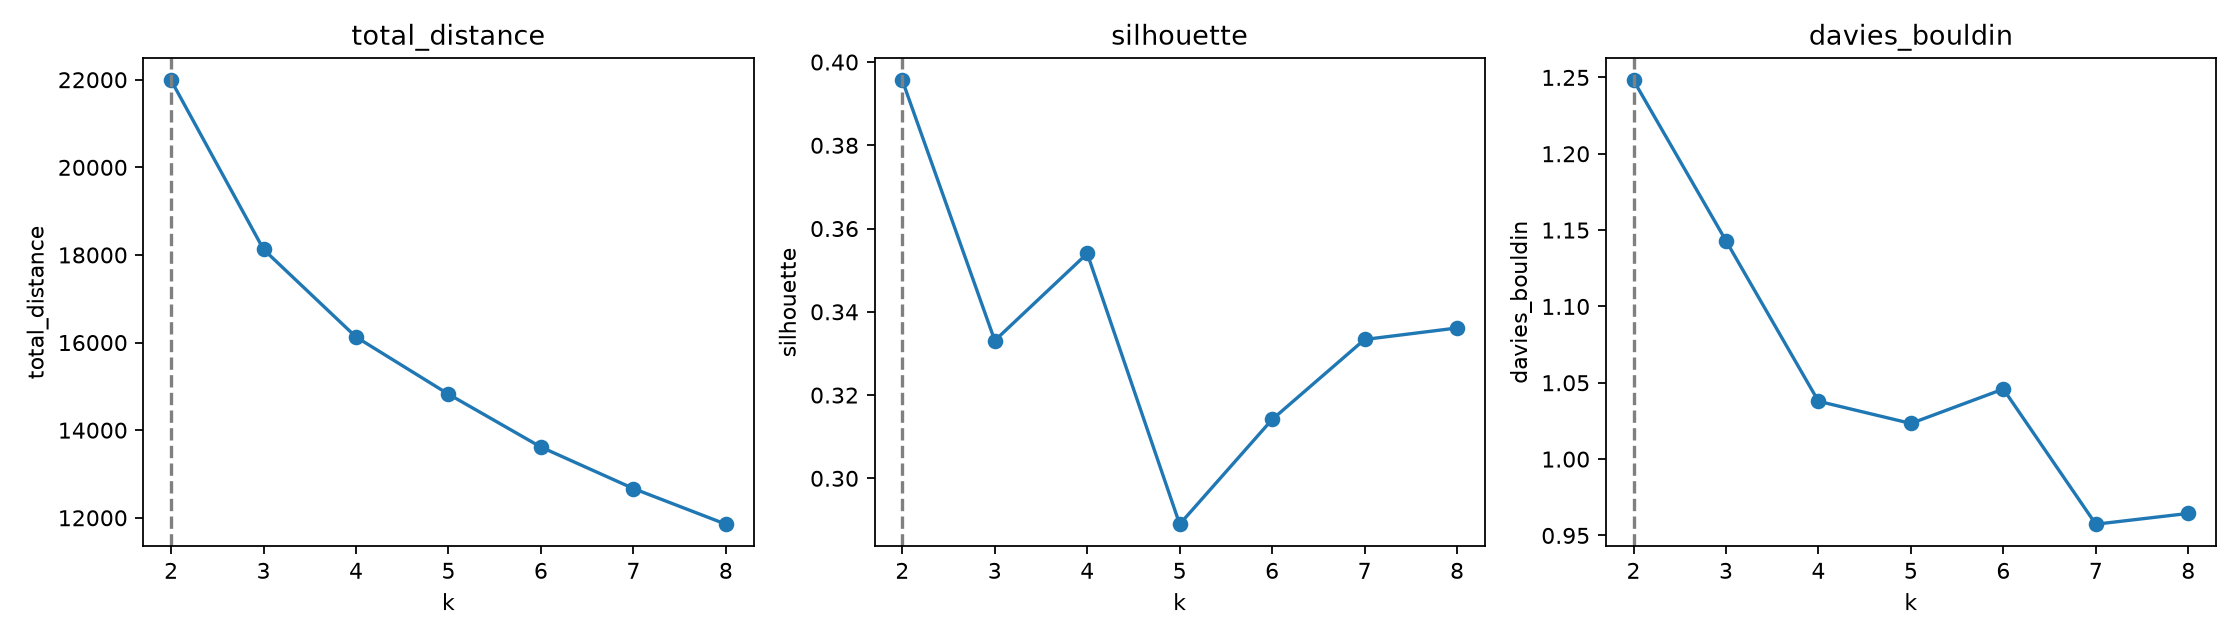

**Cara membaca:** kiri adalah jumlah jarak ke medoid (turun saat k naik, tidak ada titik siku tegas); tengah Silhouette, lebih tinggi lebih baik; kanan Davies-Bouldin, lebih rendah lebih baik. Garis putus-putus menandai k terpilih.

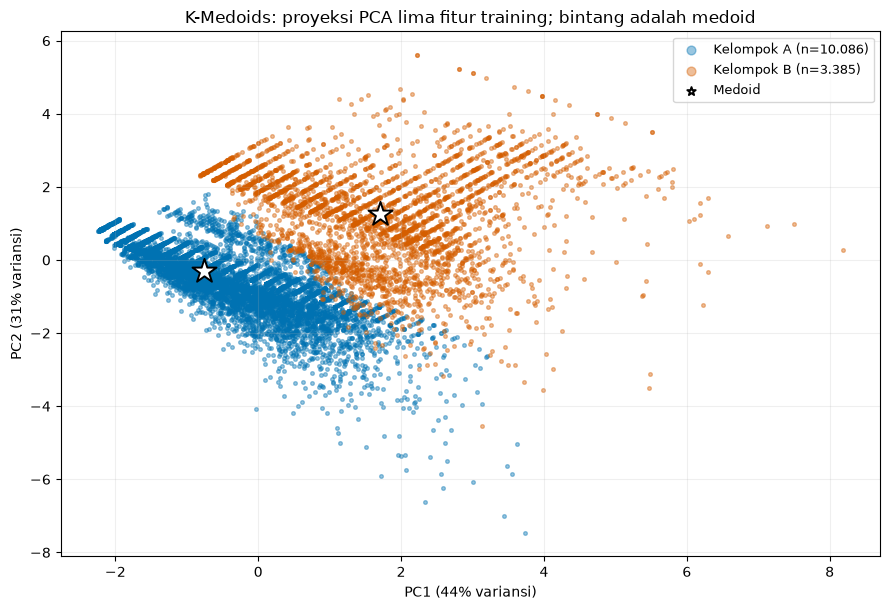

**Cara membaca:** setiap titik adalah satu kotak-triwulan training pada dua sumbu PCA. PCA hanya alat visual, model dilatih pada lima fitur standar penuh. Bintang putih adalah medoid, yaitu titik data nyata, bukan titik rata-rata.

profile
NO_EVENTS      21689
KMEDOIDS_P0    10086
KMEDOIDS_P1     3385
Name: n_grid_quarters, dtype: int64

In [8]:
from sklearn.decomposition import PCA

display(Image(filename=str(ROOT / "reports/figures/kmedoids_selection.png")))
display(Markdown("**Cara membaca:** kiri adalah jumlah jarak ke medoid (turun saat k naik, tidak ada titik siku tegas); tengah Silhouette, lebih tinggi lebih baik; kanan Davies-Bouldin, lebih rendah lebih baik. Garis putus-putus menandai k terpilih."))
palette = ["#0072B2", "#D55E00", "#009E73", "#CC79A7", "#E69F00", "#56B4E9", "#332288", "#882255"]
pca = PCA(n_components=2, random_state=42).fit(kmedoids_X)
projection = pca.transform(kmedoids_X)
medoid_projection = pca.transform(kmedoids_model.cluster_centers_)
fig, ax = plt.subplots(figsize=(9, 6.2))
for number in range(kmedoids_model.n_clusters):
    mask = kmedoids_model.labels_ == number
    ax.scatter(projection[mask, 0], projection[mask, 1], s=7, alpha=.4, color=palette[number % len(palette)],
               label=f"Kelompok {chr(65 + number)} (n={jumlah(mask.sum())})")
ax.scatter(medoid_projection[:, 0], medoid_projection[:, 1], marker="*", s=330, color="white", edgecolor="black", linewidth=1.4, zorder=5, label="Medoid")
ax.set(xlabel=f"PC1 ({pca.explained_variance_ratio_[0]:.0%} variansi)", ylabel=f"PC2 ({pca.explained_variance_ratio_[1]:.0%} variansi)",
       title="K-Medoids: proyeksi PCA lima fitur training; bintang adalah medoid")
legend = ax.legend(fontsize=9)
for handle in legend.legend_handles:
    handle.set_sizes([40])
ax.grid(alpha=.2)
fig.tight_layout()
fig.savefig(ROOT / "reports/figures/kmedoids_pca_medoids.png", dpi=160)
plt.show()
plt.close(fig)
display(Markdown("**Cara membaca:** setiap titik adalah satu kotak-triwulan training pada dua sumbu PCA. PCA hanya alat visual, model dilatih pada lima fitur standar penuh. Bintang putih adalah medoid, yaitu titik data nyata, bukan titik rata-rata."))
display(labels["profile"].value_counts().rename("n_grid_quarters"))


## Referensi dan batas interpretasi

[Dokumentasi EMSC](https://www.seismicportal.eu/fdsn-wsevent.html), [clustering scikit-learn](https://scikit-learn.org/stable/modules/clustering.html), dan docs/metodologi.md. Hasil adalah profil aktivitas katalog dalam bounding box dan periode yang dipilih. Interpretasi risiko, prediksi kejadian gempa, serta klaim perubahan fisik memerlukan bukti tambahan.